<a href="https://colab.research.google.com/github/Tiyinolalekan/Deep_Learning_Image_Classifier/blob/main/Copy_of_Second_Stage_Clothing_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***SECOND STAGE : CLOTHING SPECIALIST***

This notebook builds, trains, validates and tests a CNN model that will classify clothing apparels into their respective subcategories by utilising transfer learning for higher accuracy.

Relevant library imports.

In [21]:
#Imports
import torch #Main PyTorch library
import torch.nn as nn # Neural network compnents
import torch.optim as optim #Optimisers for training
import torchvision #Computer-vision datasets/tools
from torchvision import datasets, models #Importing datasets and models
import torchvision.transforms as transforms #Preparing images
import matplotlib.pyplot as plt #to visualise images
from torch.utils.data import DataLoader
from torchvision.utils import make_grid
import time
import copy
import numpy as np
import pandas as pd

#CHECKING IMPORTS AND RUNTIME
print(torch.__version__)
print(torch.cuda.is_available()) #Checking if a GPU is available

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') ##Resulting to use CPU if GPU isnt available. GPU is preferred cause it performs multiple AI mathematical calculations faster
print(device)

2.14.1+cu130
True
cuda


Accessing the pre-trained model.

In [ ]:
AlexNet = models.alexnet(pretrained=True)
AlexNet

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 193MB/s]


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

Mounting google drive folder to retrive stored dataset

In [3]:
#Mounting google drive into content folder
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Copying dataset from drive folder into a more accessible folder

In [4]:
!mkdir -p /content/data
!cp -r /content/drive/MyDrive/neura_data/clothes /content/data/

Checking data copied over correctly

In [22]:
!find /content/data/clothes/train -type f | wc -l

21480


Constructing paths to dataset folders

In [23]:
from pathlib import Path

print(Path("/content/data/clothes").exists()) #checking if file exists
#print(Path("neura_data/router_dataset/val").exists())

root_path = "/content/data/clothes"
train_dir = root_path + "/train"
val_dir = root_path + "/val"
test_dir = root_path + "/test"
print(Path(train_dir).exists())
print(Path(val_dir).exists())
print(Path(test_dir).exists())

True
True
True
True


**Normalisation using empirically determined mean and standard deviation values.**

In [24]:
mean = [0.485, 0.456, 0.406] #Imperatively found as studies show
std = [0.229, 0.224, 0.225]

**De-normalise the images**

In [25]:
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)

**Transformations**: Transforming the data using the torchvision library.

In [26]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),  #Resezies to 224x224 pixels to match the original VGG-16 network
    transforms.RandomHorizontalFlip(), #Default 0.5 i.e., 50% chance of image being flipped
    transforms.ToTensor(),  #Converting it to tensors
    transforms.Normalize(mean, std) #Normalising the images (will need to denormalise to view images properly)
])

#Copy of dataset for examples/checks below
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform
)

Peeking at class structure

In [27]:
print(train_dataset.classes)

['dress', 'hat', 'hoodie', 'longsleeve', 'outwear', 'pants', 'shirt', 'shoes', 'shorts', 'skirt', 't-shirt']


Naming Classes

In [50]:
classes = ['dress', 'hat', 'hoodie', 'longsleeve', 'outwear', 'pants', 'shirt', 'shoes', 'shorts', 'skirt', 't-shirt']

#Peeking
image, label = train_dataset[0]
print(image.shape) #First element represents the number of color channels,a nd remaning two is the height and width based on the number of pixels
print(label)
print(classes[label])

torch.Size([3, 224, 224])
0
dress


Displaying a test image using matplotlib to ensure the images load in correctly

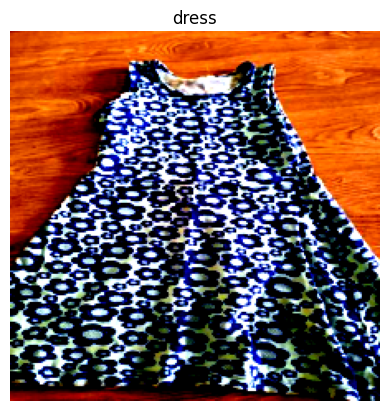

In [51]:
#Displaying image using matplotlib

plt.imshow(image.permute(1,2,0)) #rearranged dimensions to be height, width and channels where, 0,1,2 are indicies from the image.shape array e.g., [3,32,32] becomes (32,32,3)
plt.title(classes[label])
plt.axis("off")
plt.show()

# ***CREATING THE MODEL***

In [55]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #Using the CPU to train if no GPU's are detected

class CNN(nn.Module): #Inheritnce class
  def __init__(self):
    super().__init__()
    #BLOCK ONE
    self.block1 = nn.Sequential(
          #First Convolutional layer
                  nn.Conv2d(
                      in_channels=3,
                      out_channels=64,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(64),
                  nn.ReLU(inplace=True),
              #Second Convolution
              #Do two times the convolution in the FIRST block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=64,
                        out_channels=64,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(64),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

      #BLOCK TWO
    self.block2 = nn.Sequential(
          #Third Convolutional layer
                  nn.Conv2d(
                      in_channels=64,
                      out_channels=128,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(128),
                  nn.ReLU(inplace=True),
              #Fourth Convolution
              #Do two times the convolution in the Second block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=128,
                        out_channels=128,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(128),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

      #BLOCK THREE
    self.block3 = nn.Sequential(
          #Fifth Convolutional layer
                  nn.Conv2d(
                      in_channels=128,
                      out_channels=256,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),
              #sixth Convolution
                nn.Conv2d(
                        in_channels=256,
                        out_channels=256,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),

          #seventh Convolution
              #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=256,
                        out_channels=256,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(256),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )


      #BLOCK FOUR
    self.block4 = nn.Sequential(
          #Eight Convolutional layer
                  nn.Conv2d(
                      in_channels=256,
                      out_channels=512,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
              #Ninth Convolution
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
          #Tenth Convolution
        #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )
      #BLOCK 5
    self.block5 = nn.Sequential(
          #Eleventh Convolutional layer
                  nn.Conv2d(
                      in_channels=512,
                      out_channels=512,
                      kernel_size=3,
                      padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
              #Twelfth Convolution
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
          #Thirteenth Convolution
        #Do three times the convolution in the Third block according to VGG model to boost accuracy
                nn.Conv2d(
                        in_channels=512,
                        out_channels=512,
                        kernel_size=3,
                        padding=1
                      ),

                  nn.BatchNorm2d(512),
                  nn.ReLU(inplace=True),
                  nn.MaxPool2d(2) # where kernel_size=2 stride=2
          )

    self.dropout = nn.Dropout(0.5) #Randomly deactivating neurons by zeroing out a fraction of neurons in a layer to provent overfittig
    self.relu = nn.ReLU(inplace=True)

    #Fully Connected layer one
    self.fc1 = nn.Linear(25088, 4096)  #batch is flattened to 25088 as block 5 produced 512 slices and each has a height of 7x7 after pooling. Therefore; 512 x 7 x 7 = 25088. Output neurons of 4096 to match the VGG-16 Network.

    #Fully Connected layer two
    self.fc2 = nn.Linear(4096, 4096)  #Learning a more complex combination of the 4096 neurons from the first conncted layer before final prediction

    #Fully Connected layer three
    self.fc3 = nn.Linear(4096, 11)  #flattening the final layer to predict from the 11 classes in the dataset

  def forward(self, x):
      #Using the blocks assemebeled and applying them sequentially to the variable
      x= self.block1(x)
      x= self.block2(x)
      x= self.block3(x)
      x= self.block4(x)
      x= self.block5(x)


      x= torch.flatten(x, 1)  #Flattening the one dimention
      x = self.fc1(x) #Fully connected layer
      x = self.relu(x)
      x = self.dropout(x) #Randomly deactivating neuraons by zeroing out a fraction of neurons in a layer to provent overfittig
      x = self.fc2(x)
      x = self.relu(x)
      x = self.dropout(x)
      x = self.fc3(x)

      return x

In [56]:
 #Instantiate and move to device
model = CNN()
model = model.to(device) #Moving to GPU if avilable

Checking if Cuda is being used

In [57]:
print(device)                           # should say cuda
print(next(model.parameters()).device)  # should say cuda:0

cuda
cuda:0


Loading the data into the model

In [58]:
#Getting test data from their folders
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform
)
#torch.manual_seed(42) #Seeding the dataset to get the same results all the time
#Loading the data in batches of 64 then shuffling it to enable randomisation and efficient learning
train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=64, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=64, shuffle=False
)

#Calculating sample weights to handle dataset imbalance
counts = torch.bincount(torch.tensor(train_dataset.targets))
sample_weights = len(train_dataset) / (len(counts) * counts.float())

#Loss Function
criterion = nn.CrossEntropyLoss(weight=sample_weights.to(device)) #Produce sample losses instaed of combining all losses in order to initiate sample weights to handle dataset imbalance.

#Optimizer
optimizer = optim.Adam( #the algorithm we're using to update the weights
    model.parameters(),#all the weights and biases the model can learn
    lr=0.001 #learning rate, controlling how big each weight update is
)

Peeking into the dataset

In [53]:
print(train_dataset)
print(test_dataset)
print(val_dataset)

print()
print(len(train_dataset))
print(len(test_dataset))
print(len(val_dataset))

Dataset ImageFolder
    Number of datapoints: 21216
    Root location: /content/data/clothes/train
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
Dataset ImageFolder
    Number of datapoints: 2676
    Root location: /content/data/clothes/test
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
           )
Dataset ImageFolder
    Number of datapoints: 2665
    Root location: /content/data/clothes/val
    StandardTransform
Transform: Compose(
               Resize(size=(224, 224), interpolation=bilinear, max_siz

Displaying Image Batch

Lables:  [ 7  4  2  7  7  5 10  4  6  9 10  6  5 10  5  8  7 10  7  6 10  6 10 10
  7  5  6  7  5  4  4  5 10  6  5  1  2  5  7  5 10  7 10  5 10 10  7 10
  7  7  0 10  4  2 10 10  7  6  5 10 10  2 10  7]
Classes:  shoes outwear hoodie shoes shoes pants t-shirt outwear shirt skirt t-shirt shirt pants t-shirt pants shorts shoes t-shirt shoes shirt t-shirt shirt t-shirt t-shirt shoes pants shirt shoes pants outwear outwear pants t-shirt shirt pants hat hoodie pants shoes pants t-shirt shoes t-shirt pants t-shirt t-shirt shoes t-shirt shoes shoes dress t-shirt outwear hoodie t-shirt t-shirt shoes shirt pants t-shirt t-shirt hoodie t-shirt shoes


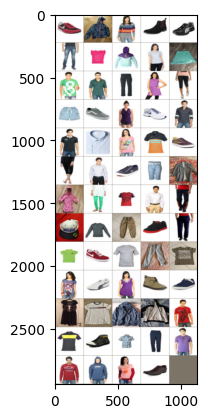

In [43]:
for images, labels in train_loader:
  break #only labels

print('Lables: ', labels.numpy())
print("Classes: ", *np.array([classes[i] for i in labels]))

im = make_grid(images, nrow=5)
im_inv = inv_normalize(im) #De normalising images
plt.imshow(np.transpose(im_inv.numpy(), (1,2,0)))
plt.show()

Leakage Check

In [48]:
import hashlib, os

def file_hashes(folder):
    out = set()
    for r, _, fs in os.walk(folder):
        for f in fs:
            with open(os.path.join(r, f), "rb") as fh:
                out.add(hashlib.md5(fh.read()).hexdigest())
    return out

tr, va, te = file_hashes(train_dir), file_hashes(val_dir), file_hashes(test_dir)
print("train/test overlap:", len(tr & te))
print("train/val overlap: ", len(tr & va))
print("val/test overlap:  ", len(va & te))

print()




train/test overlap: 0
train/val overlap:  0
val/test overlap:   0



# ***MAIN TRAINING LOOP***

In [ ]:
num_epochs = 10 #the model goes through the entire 50,000-image training dataset 10 times.
train_losses = []



for epoch in range(num_epochs) :

  model.train() #Training the model
  running_loss = 0.0

  for images, labels in train_loader: #Iterating through the 64/9000+ -image training dataset

    images = images.to(device) #Inputs
    labels = labels.to(device) #Outputs


    optimizer.zero_grad() #clears the gradients from the previous batch
    outputs = model(images) #forward pass; the CNN makes predictions.

    #outputs are raw logits; CrossEntropyLoss handles softmax internally
    loss = criterion(outputs, labels) #* sample_weights).mean() # calculates how wrong those predictions are.
    loss.backward() #backpropagation; calculates the gradient for EVERY learnable weight.

    optimizer.step() #uses those gradients to update the weights.

    running_loss += loss.item()

  epoch_loss = running_loss/len(train_loader)
  train_losses.append(epoch_loss)
  print(
        f"Epoch {epoch+1}/{num_epochs},"
        f"Loss: {epoch_loss:.4f}"
    )

Epoch 1/10,Loss: 2.5104
Epoch 2/10,Loss: 2.1984
Epoch 3/10,Loss: 2.1997
Epoch 4/10,Loss: 2.1881
Epoch 5/10,Loss: 2.1768


***MODEL EVALUATION***

In [ ]:
def evaluation(model, loader):
  model.eval()  #Entering evaluation mode
  correct = 0  #number of correct guesses
  total = 0 #total number of predictions

  with torch.no_grad(): #no gradients needed cause model is learning not measuring

    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = model(images) #logits for each test image So outputs has shape [64, 3]: 64 rows (one per image) and 3 columns (one score per class).
        _, predicted = torch.max(outputs,1) #Returns the class with the highest logit
        total += labels.size(0) #Getting the total number of images in the batch
        correct += (predicted == labels).sum().item()  #how many were right. .item() pulls that single value out of the tensor as a plain Python number


  accuracy = 100 * correct / total
  print(f"Test Accuracy: {accuracy:.2f}%")



In [ ]:
test_eval = evaluation(model, test_loader)


Test Accuracy: 89.95%


In [ ]:
train_eval = evaluation(model, train_loader)

Test Accuracy: 89.99%


In [ ]:
val_eval = evaluation(model, val_loader)

Test Accuracy: 89.57%


***BASELINE UPON FIRST EVER RUN***:
_____________________________


*   Final Training Loss: 0.7171
*   Test Accurracy: 70.14%
*   Validation Accuracy: 72.69%
*   Training Accuracy: 70.33%
*   Gap (between test and train):approximately 0.19 points.



***Loss Curve***

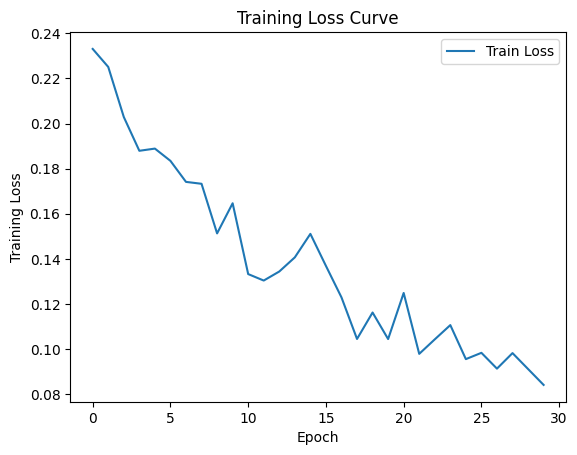

In [ ]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss Curve')
plt.ticklabel_format(style='plain', axis='y')
plt.legend()
plt.show()

# ***DEBUGGING CELLS***

Checking location and size of the dataset and its stored images

In [ ]:
#Checking location and size of the dataset and its stored images
import os
from PIL import Image

path = train_dir          # paste your real path
print(path)                           # does it start with /content/drive ?

for root, _, files in os.walk(path):
    if files:
        img = Image.open(os.path.join(root, files[0]))
        print(img.size, round(os.path.getsize(os.path.join(root, files[0])) / 1e6, 2), "MB")
        break

/content/data/router_dataset/train
(2621, 2736) 0.54 MB


Checking how big the images are

In [ ]:
import os, random
from PIL import Image

files = [os.path.join(r, f) for r, _, fs in os.walk(train_dir) for f in fs]
print(len(files), "files")

sample = random.sample(files, min(200, len(files)))
widths = sorted(Image.open(f).size[0] for f in sample)
print("width min / median / max:", widths[0], widths[len(widths)//2], widths[-1])

9006 files
width min / median / max: 100 384 2736


Getting Loading time of the model

In [60]:

#Getting loading time of the model
import time

print(device, next(model.parameters()).device)
print(len(train_loader), "batches per epoch")

model.train()
t_load = t_comp = 0
end = time.time()
for i, (images, labels) in enumerate(train_loader):
    t_load += time.time() - end
    t0 = time.time()
    images, labels = images.to(device), labels.to(device)
    optimizer.zero_grad()
    loss = criterion(model(images), labels)
    loss.backward()
    optimizer.step()
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_comp += time.time() - t0
    end = time.time()
    if i == 19:
        break

print(f"loading: {t_load:.1f}s, compute: {t_comp:.1f}s for 20 batches")
print("estimated epoch (min):", round((t_load + t_comp) / 20 * len(train_loader) / 60, 1))

cuda cuda:0
332 batches per epoch
loading: 4.1s, compute: 20.9s for 20 batches
estimated epoch (min): 6.9


Removing Duplicates

In [45]:
import hashlib, os

def get_file_hashes(path):
    with open(path, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()  # calculating unique hash for passed file path

def get_hashes(folder):
    hashes = set()
    for r, _, fs in os.walk(folder):
        for f in fs:
            hashes.add(get_file_hashes(os.path.join(r, f)))  # adding all unique file hashes in the folder to a set
    return hashes


def remove_duplicates(train_dir, test_dir, val_dir):
    # Getting test dataset hashes
    test_hashes = get_hashes(test_dir)
        # Validation must not overlap with test or train
    val_hashes = get_hashes(val_dir)
    val_deleted = 0


    train_deleted_tests = 0  # Number of duplicate test data deleted
    train_deleted_val = 0  # Number of duplicate val data deleted

    # Iterating through the train dataset to check for duplicates
    for root, _, files in os.walk(train_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in test_hashes:  # comparing test data first to training data
                os.remove(path)  # deleting duplicate if fuond
                train_deleted_tests += 1  # incrementing deleted values

    for root, _, files in os.walk(train_dir):
        for file in files:
            path_v = os.path.join(root, file)
            if get_file_hashes(path_v) in val_hashes:
                os.remove(path_v)
                train_deleted_val += 1

    print("Deleted", train_deleted_tests, "test files")
    print("Deleted", train_deleted_val, "val files")

remove_duplicates(train_dir, test_dir, val_dir) # Recalculate hashes after cleaning training
train_hashes = get_hashes(train_dir)











Deleted 146 test files
Deleted 118 val files


Removing duplicates in test and val datasets

In [47]:
def remove_test_val_duplicates(test_dir, val_dir):
    test_hashes = get_hashes(test_dir)
    val_hashes = get_hashes(val_dir)
    test_deleted = 0
    val_deleted = 0
    for root, _, files in os.walk(test_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in val_hashes:
                os.remove(path)
                test_deleted += 1
    for root, _, files in os.walk(val_dir):
        for file in files:
            path = os.path.join(root, file)
            if get_file_hashes(path) in test_hashes:
                os.remove(path)
                val_deleted += 1
    print("Deleted", test_deleted, "test files")
    print("Deleted", val_deleted, "val files")

remove_test_val_duplicates(test_dir, val_dir)

Deleted 20 test files
Deleted 20 val files
